<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QNN_DDoS_Kucukkara2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QNN for DDoS detection: the Küçükkara, Atban and Bayılmış (2024) paper step by step

This notebook rebuilds the experiment of one paper:

Muhammed Yusuf Küçükkara, Furkan Atban, Cüneyt Bayılmış, "Quantum-Neural Network Model for Platform Independent DDoS Attack Classification in Cyber Security", *Advanced Quantum Technologies* 7(10), 2400084, 2024. DOI [10.1002/qute.202400084](https://doi.org/10.1002/qute.202400084) (open access).

The paper trains a quantum neural network (QNN) built from Qiskit Machine Learning's `QNNCircuit` + `EstimatorQNN` + `NeuralNetworkClassifier` on a small, class-balanced subset of the CIC-DDoS2019 dataset with seven selected features (one qubit per feature) and reports 92.63 % accuracy on IBM's statevector simulator and 80.69 % on a local machine for 16,000 flows.

**What this notebook does.** It downloads CIC-DDoS2019 files by itself, cleans them, builds the balanced subsets of the paper (1,000 to 16,000 flows), selects the paper's seven features, trains the same Qiskit QNN with the same optimiser (COBYLA, 100 iterations), trains classical baselines on exactly the same seven numbers, redraws the paper's Table 3 and Figure 5, tests the paper's "local versus simulator" claim, and ends with a verdict for every number the paper reports.

**How to run it.** Open the file in Google Colab, keep the normal CPU runtime and choose Runtime, then Run all. No GPU and no IBM account are needed. With `FAST_MODE = True` (default) the whole notebook takes about 10 minutes; `FAST_MODE = False` runs the paper's full data-size sweep and takes about an hour on a CPU.

**What you get at the end.** Your own accuracy, precision, recall and F1 for the QNN and for the classical baselines at every data size, side by side with the paper's Table 3, plus a critical reading of the paper.

## 1. The paper in one page

**Problem.** Detect distributed denial of service (DDoS) flows in network traffic. Each flow (one conversation between two hosts) is summarised by about 80 numbers computed by CICFlowMeter; the model must say *benign* or *attack*.

**Method.** A quantum neural network from the Qiskit Machine Learning tutorial: a `ZZFeatureMap` encodes the seven features into seven qubits, a `RealAmplitudes` ansatz holds the trainable weights, an `Estimator` measures one expectation value, and `NeuralNetworkClassifier` turns its sign into the class. The weights are tuned with COBYLA for 100 iterations.

**Data.** CIC-DDoS2019 (Sharafaldin et al., 2019). The paper starts from 431,370 flows, removes 5,449 rows with zero, null or duplicate values, and draws class-balanced subsets of 1,000, 2,000, 4,000, 8,000 and 16,000 flows (half attack, half benign). The paper does not say which attack types or which CSV files it used.

**Preprocessing.** Two label-like columns removed; 12 constant, repeated or null columns removed (80 to 66 features); `SelectKBest` with the F score keeps seven features: Fwd Packet Length Min, Fwd Packet Length Mean, Flow Bytes/s, Packet Length Min, Packet Length Max, Avg Packet Size, Avg Fwd Segment Size; then Min-Max normalisation.

**Claims (Table 3 of the paper).** Accuracy, precision, recall and F1 for each subset size, once trained "on a local computer" and once "on the IBM statevector simulator":

| flows | local acc | local F1 | simulator acc | simulator prec | simulator rec | simulator F1 |
|---|---|---|---|---|---|---|
| 1,000 | 70.33 % | 70.33 % | 82.33 % | 80.27 % | 83.10 % | 81.66 % |
| 2,000 | 73.67 % | 72.76 % | 85.83 % | 87.07 % | 86.25 % | 86.66 % |
| 4,000 | 75.50 % | 76.89 % | 84.75 % | 86.09 % | 84.29 % | 85.18 % |
| 8,000 | 79.63 % | 80.50 % | 87.54 % | 87.80 % | 88.56 % | 88.18 % |
| 16,000 | 80.69 % | 79.21 % | **92.63 %** | 91.38 % | 92.85 % | 92.11 % |

(The full local precision and recall columns are typed into the comparison cell in Section 14.) The paper also claims that accuracy grows with the amount of data, and that the simulator beats the local run because IBM's machines use "higher precision arithmetic".

### What follows the paper and what had to be chosen

The paper leaves several things unspecified. Each choice below is also marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Dataset files | "a subset of CIC-DDoS2019", 431,370 flows, attack types not named | `01-12/DrDoS_NTP.csv` (645 MB, 1.2 M flows, NTP reflection attack) from a public Hugging Face mirror. Chosen because `SelectKBest` on this file picks five of the paper's seven features (on the UDP-Lag file it picks none of them) and because it holds 13,317 distinct benign flows, enough for the 16,000-flow subset. |
| Duplicate removal | "zero, null or duplicate values" removed (5,449 rows) | ±inf and NaN rows dropped, then exact duplicates on the feature columns dropped (this removes most attack rows of CIC-DDoS2019, which are near-identical floods) |
| Subset sizes | 1,000, 2,000, 4,000, 8,000, 16,000 balanced | `FAST_MODE`: 1,000 and 2,000; full run: all five sizes, nested (every larger subset contains the smaller one) |
| Attack rows kept | all 431,370 flows loaded | every benign flow and a random 10 % of the attack flows of each 200,000-row chunk (the subsets never need more) |
| Train/test split | not stated; every accuracy in Table 3 is an exact fraction of 30 % of the subset (e.g. 92.63 % = 4446/4800) | stratified 70/30 split with `random_state=SEED` |
| Seven features | the seven names listed above (CIC-IDS-2017 spelling) | the same seven columns of the CIC-DDoS2019 CSV (`Min Packet Length`, `Max Packet Length`, `Average Packet Size` are the CSV spellings); `SelectKBest` is re-run on the training split only to compare its ranking with the paper's list |
| Min-Max range | "Min-Max normalisation" (range not given) | `MinMaxScaler((0, 1))` fitted on the training split, test values clipped to [0, 1] |
| Feature map / ansatz | `ZZFeatureMap` and `RealAmplitudes` (Figure 2), repetitions and entanglement not given | `zz_feature_map(7, reps=2, entanglement="linear")` (the library default `"full"` has 21 pairs per repetition, doubles the simulation time and gave no gain in our tests; Exercise 6), `real_amplitudes(7, reps=3, entanglement="reverse_linear")` (library default), 28 weights |
| Observable / loss / labels | `EstimatorQNN` with `NeuralNetworkClassifier` (defaults implied) | observable Z on all seven qubits, squared-error loss, labels +1 attack / −1 benign (the Qiskit tutorial's convention) |
| Optimiser | COBYLA, 100 iterations | `COBYLA(maxiter=100)`; note that 100 counts function evaluations and 30 of them are the initial simplex for 28 weights |
| Simulator | IBM `simulator_statevector` through the Runtime Estimator, and a "local" run | Qiskit Aer `EstimatorV2` with exact expectation values (`default_precision=0`); the same weights are re-evaluated with `StatevectorEstimator`, with a by-hand NumPy statevector, and with simulated shot noise |
| Classical baseline | none in the paper (comparison with other papers only) | Random forest, RBF SVM, logistic regression and a small MLP on the identical seven Min-Max numbers, plus a random forest on all features |
| Repetitions | single run per size | `N_RUNS` seeds at the smallest size, mean ± std |

## 2. Install the libraries

Colab already has NumPy, pandas, scikit-learn and Matplotlib. We add Qiskit, Qiskit Machine Learning (the QNN classes), Qiskit Aer (the fast simulator), `pylatexenc` (circuit drawings) and `huggingface_hub` (the dataset download). The versions are the ones this notebook was tested with. If Colab asks to restart the session after this cell, accept and run again from the next cell.

In [1]:
%pip -q install "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" pylatexenc huggingface_hub

Note: you may need to restart the kernel to use updated packages.


## 3. Settings

Every number you may want to change is in this cell. `FAST_MODE = True` keeps the run at about 10 minutes (the two smallest subsets of the paper); `FAST_MODE = False` runs all five subset sizes of the paper, which takes about an hour on a CPU because the 16,000-flow subset means 11,200 training circuits per COBYLA evaluation.

In [2]:
SEED = 42                     # every random choice in the notebook depends on this
FAST_MODE = False              # True: about 10 minutes; False: the paper's full data-size sweep

N_QUBITS = 7                  # paper: one qubit per selected feature, seven features
TEST_SIZE = 0.30              # CHOICE: not stated; deduced from Table 3 (all accuracies are k/(0.3*N))
DATA_SIZES = [1000, 2000] if FAST_MODE else [1000, 2000, 4000, 8000, 16000]   # paper: all five
MAXITER = 100                 # paper: COBYLA for 100 iterations
N_RUNS = 3 if FAST_MODE else 5  # CHOICE: repeated seeds at the smallest subset size (paper: one run)

FM_REPS, FM_ENTANGLEMENT = 2, "linear"                 # CHOICE: reps as the library default; linear pairs (full = 21 pairs, 2x slower, no gain)
ANSATZ_REPS, ANSATZ_ENTANGLEMENT = 3, "reverse_linear"  # CHOICE: real_amplitudes library defaults
PRECISION = 0.0               # CHOICE: exact expectation values (EstimatorQNN's default is 1/64 = shot noise)
NOISE_PRECISION = 1 / 64      # used only in the "platform" check: standard error of a 4,096-shot estimate
ANGLE_RANGE = (0.0, 1.0)      # CHOICE: plain Min-Max as in the paper (range not stated)

DATA_SOURCE = "huggingface"   # "huggingface" (automatic) or "path" (CSV files already on disk)
DATA_DIR = "data"             # download cache; relative to the working directory
HF_REPO = "baalajimaestro/CICDDoS2019"       # public copy of the original CIC-DDoS2019 CSV files
HF_FILES = ["01-12/DrDoS_NTP.csv", "03-11/Portmap.csv", "01-12/UDPLag.csv"]   # CHOICE: NTP reflection attack; more files only if benign flows run short
LOCAL_FILES = []              # used only when DATA_SOURCE == "path"
ATTACK_FRACTION = 0.10        # share of attack rows kept from each chunk (benign rows are all kept)

# CHOICE: the paper's seven features, spelled as in the CIC-DDoS2019 CSV header
PAPER_FEATURES = {
    "Fwd Packet Length Min": "Fwd Packet Length Min",
    "Fwd Packet Length Mean": "Fwd Packet Length Mean",
    "Flow Bytes/s": "Flow Bytes/s",
    "Packet Length Min": "Min Packet Length",
    "Packet Length Max": "Max Packet Length",
    "Avg Packet Size": "Average Packet Size",
    "Avg Fwd Segment Size": "Avg Fwd Segment Size",
}
FEATURES = list(PAPER_FEATURES.values())
LABEL_NAMES = ["benign (-1)", "attack (+1)"]

## 4. Imports and seeds

`algorithm_globals.random_seed` controls the initial weights that `NeuralNetworkClassifier` draws; `seed_simulator` controls the Aer simulator; scikit-learn gets `random_state=SEED` everywhere.

In [3]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import clear_output

from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

import qiskit, qiskit_aer, qiskit_machine_learning
from qiskit.circuit.library import zz_feature_map, real_amplitudes
from qiskit.quantum_info import Statevector, Operator, SparsePauliOp
from qiskit.primitives import StatevectorEstimator
from qiskit_aer.primitives import EstimatorV2 as AerEstimator
from qiskit_machine_learning.circuit.library import qnn_circuit
from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.algorithms import NeuralNetworkClassifier
from qiskit_machine_learning.optimizers import COBYLA
from qiskit_machine_learning.utils import algorithm_globals

warnings.filterwarnings("ignore")
algorithm_globals.random_seed = SEED
rng = np.random.default_rng(SEED)

def seconds_since(start):
    return float(np.subtract(time.perf_counter(), start))

print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__,
      "| qiskit-aer", qiskit_aer.__version__)
print("FAST_MODE =", FAST_MODE, "| subset sizes", DATA_SIZES, "| COBYLA evaluations", MAXITER)

qiskit 2.5.2 | qiskit-machine-learning 0.9.1 | qiskit-aer 0.17.2
FAST_MODE = False | subset sizes [1000, 2000, 4000, 8000, 16000] | COBYLA evaluations 100


## 5. Get the data

### What CIC-DDoS2019 is

The Canadian Institute for Cybersecurity recorded a test network on two days (12 January and 11 March 2019) while launching twelve kinds of reflection and exploitation DDoS attacks against it; benign traffic came from the B-Profile generator that imitates human users. CICFlowMeter-V3 cut the packets into flows and computed about 80 statistics per flow (packet lengths, inter-arrival times, flags, ...). Each CSV file holds the flows of one attack plus the benign flows of that period.

### Which file we use and why

The original files are large (22 GB in total; the file for the DNS attack alone is 2 GB). The paper does not say which file(s) it used, only that its seven features are packet-length statistics. Those statistics separate *reflection* attacks (the attacker makes servers answer with large packets) from benign traffic very well, and indeed when we re-run `SelectKBest` on the NTP reflection file it returns five of the paper's seven features (Section 7). On the UDP-Lag file, by contrast, none of the paper's features makes the top seven and the paper's pipeline only reaches about 82 %. We therefore use `01-12/DrDoS_NTP.csv` (645 MB, 1,217,007 flows) from a public Hugging Face copy. It is also the smallest file with enough benign flows for the 16,000-flow subset: CIC-DDoS2019 has very few benign flows (a few thousand per file, 14,365 here), and many attack flows are exact copies of each other once the IP addresses and timestamps are removed.

The code reads the file in pieces of 200,000 rows so that Colab's memory does not fill up, keeps every benign flow and a random 10 % of the attack flows per chunk, cleans them, and would download the next file in `HF_FILES` only if the largest subset still lacked distinct benign flows. If the Hugging Face copy is ever unavailable, download the CSV files from the dataset page at unb.ca (CIC, datasets, DDoS 2019), set `DATA_SOURCE = "path"` and list them in `LOCAL_FILES`.

In [4]:
ID_COLUMNS = ["Unnamed: 0", "Flow ID", "Source IP", "Source Port", "Destination IP",
              "Destination Port", "Timestamp", "SimillarHTTP"]   # identifiers, not behaviour

def download(repo, filename):
    from huggingface_hub import hf_hub_download
    print("Downloading", filename, "...")
    return hf_hub_download(repo_id=repo, filename=filename, repo_type="dataset", cache_dir=DATA_DIR)

def read_flows(csv_path, attack_fraction, seed):
    # Read one CIC-DDoS2019 CSV in chunks: keep all benign flows and a random share of attack flows.
    # Returns the numeric feature columns plus 'y' (1 attack, 0 benign) and 'attack_type'.
    kept = []
    for chunk in pd.read_csv(csv_path, chunksize=200_000, low_memory=False):
        chunk.columns = chunk.columns.str.strip()                 # headers start with spaces
        label = chunk["Label"].astype(str).str.strip()
        is_benign = label.str.upper() == "BENIGN"
        part = pd.concat([chunk[is_benign],
                          chunk[~is_benign].sample(frac=attack_fraction, random_state=seed)])
        X = part.drop(columns=ID_COLUMNS + ["Label"], errors="ignore").apply(pd.to_numeric, errors="coerce")
        X = X.replace([np.inf, np.negative(np.inf)], np.nan)       # paper: "zero, null" values removed
        part_label = part["Label"].astype(str).str.strip()
        X["attack_type"] = np.where(part_label.str.upper() == "BENIGN", "BENIGN", part_label)
        kept.append(X[X.drop(columns=["attack_type"]).notna().all(axis=1)])
    out = pd.concat(kept, ignore_index=True)
    out["y"] = (out["attack_type"] != "BENIGN").astype(int)
    return out

benign_needed = max(DATA_SIZES) // 2
os.makedirs(DATA_DIR, exist_ok=True)
files = HF_FILES if DATA_SOURCE == "huggingface" else LOCAL_FILES
start = time.perf_counter()
frames = []
for filename in files:
    path = download(HF_REPO, filename) if DATA_SOURCE == "huggingface" else filename
    frames.append(read_flows(path, ATTACK_FRACTION, SEED))
    pool = pd.concat(frames, ignore_index=True)
    feature_cols = [c for c in pool.columns if c not in ("y", "attack_type")]
    pool = pool.drop_duplicates(subset=feature_cols).reset_index(drop=True)   # paper: duplicates removed
    n_benign = int((pool.y == 0).sum())
    print(f"  after {filename}: {len(pool):,} distinct flows, {n_benign:,} benign, "
          f"{int((pool.y == 1).sum()):,} attack  ({seconds_since(start):.0f} s)")
    if n_benign >= benign_needed:
        break

pool = pool.loc[:, (pool.nunique() > 1) | pool.columns.isin(["y", "attack_type"])]   # drop constant columns
feature_cols = [c for c in pool.columns if c not in ("y", "attack_type")]
print(f"Pool: {len(pool):,} flows, {len(feature_cols)} non-constant features (paper: 66)")
pool["attack_type"].value_counts()

  after 01-12/DrDoS_NTP.csv: 126,487 distinct flows, 13,317 benign, 113,170 attack  (39 s)


Pool: 126,487 flows, 67 non-constant features (paper: 66)


attack_type
DrDoS_NTP    113170
BENIGN        13317
Name: count, dtype: int64

### A first look

Each row is one flow. Note how different the scales are (bytes per second reach millions, packet lengths are tens of bytes) and that `Avg Fwd Segment Size` is exactly the same column as `Fwd Packet Length Mean`: CICFlowMeter computes both from the same numbers. Keep this in mind, because both are among the paper's seven features.

In [5]:
pool[FEATURES + ["attack_type"]].groupby("attack_type").describe().T.round(1).head(16)

attack_type                    BENIGN  DrDoS_NTP
Fwd Packet Length Min  count  13317.0   113170.0
                       mean      18.5      349.8
                       std       40.2      127.2
                       min        0.0        0.0
                       25%        0.0      224.0
                       50%        0.0      440.0
                       75%       38.0      440.0
                       max     2020.0     1296.0
Fwd Packet Length Mean count  13317.0   113170.0
                       mean      44.2      428.1
                       std       88.2       34.5
                       min        0.0        0.0
                       25%        0.0      429.3
                       50%       32.0      440.0
                       75%       45.0      440.0
                       max     2666.1     1296.0

In [6]:
same = np.allclose(pool["Avg Fwd Segment Size"], pool["Fwd Packet Length Mean"])
print("'Avg Fwd Segment Size' identical to 'Fwd Packet Length Mean' in every flow:", same)
share = float((pool["Min Packet Length"] == pool["Fwd Packet Length Min"]).mean())
print(f"'Min Packet Length' equal to 'Fwd Packet Length Min' in {share:.1%} of the flows")

'Avg Fwd Segment Size' identical to 'Fwd Packet Length Mean' in every flow:

 True
'Min Packet Length' equal to 'Fwd Packet Length Min' in 99.8% of the flows


## 6. The balanced subsets of the paper

The paper draws subsets of 1,000 to 16,000 flows with exactly half attack and half benign, and argues at length that balanced training data matters. We shuffle each class once with the seed and take the first `n/2` rows, so every larger subset contains the smaller one (nested subsets), then split each subset 70/30 with stratification.

**One rule that matters.** Every preprocessing step (feature scores, Min-Max ranges) is learned from the training part only and then applied unchanged to the test part. Otherwise information from the test flows leaks into the model and the scores look better than they are.

In [7]:
benign_order = pool[pool.y == 0].sample(frac=1, random_state=SEED).index
attack_order = pool[pool.y == 1].sample(frac=1, random_state=SEED).index

def balanced_subset(n_total):
    per_class = n_total // 2
    if per_class > min(len(benign_order), len(attack_order)):
        raise ValueError(f"not enough distinct flows for {n_total} balanced rows")
    idx = benign_order[:per_class].union(attack_order[:per_class])
    sub = pool.loc[idx]
    return sub[feature_cols], sub["y"]

def split(X, y, seed):
    return train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=seed)

for n in DATA_SIZES:
    X_n, y_n = balanced_subset(n)
    print(f"subset {n:>6,}: {len(X_n):,} flows, {int((y_n == 1).sum()):,} attack, {int((y_n == 0).sum()):,} benign")

subset  1,000: 1,000 flows, 500 attack, 500 benign
subset  2,000: 2,000 flows, 1,000 attack, 1,000 benign
subset  4,000: 4,000 flows, 2,000 attack, 2,000 benign
subset  8,000: 8,000 flows, 4,000 attack, 4,000 benign


subset 16,000: 16,000 flows, 8,000 attack, 8,000 benign


## 7. Feature selection: the paper's seven features

The paper ran `SelectKBest` with the F score on its 66 features and kept seven. We use exactly those seven columns, because a QNN with seven qubits needs seven numbers and the paper names them. But we also re-run `SelectKBest` on our training split to see whether it would pick the same list. (It is fitted on the training part of the largest subset only.)

In [8]:
X_big, y_big = balanced_subset(max(DATA_SIZES))
X_tr_big, X_te_big, y_tr_big, y_te_big = split(X_big, y_big, SEED)

selector = SelectKBest(f_classif, k=N_QUBITS).fit(X_tr_big, y_tr_big)
scores = pd.Series(selector.scores_, index=feature_cols).sort_values(ascending=False)
kbest_here = list(X_tr_big.columns[selector.get_support()])

print("KBest on our training split :", kbest_here)
print("Paper's seven features      :", FEATURES)
print("Overlap:", len(set(kbest_here) & set(FEATURES)), "of 7")
print("\nRank of each paper feature in our F-score ranking:")
for f in FEATURES:
    print(f"  {f:24s} rank {int(np.where(scores.index == f)[0][0]) + 1:3d}   F = {scores[f]:10.1f}")
scores.head(12).round(1)

KBest on our training split :

 ['Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Min Packet Length', 'Packet Length Mean', 'Average Packet Size', 'Avg Fwd Segment Size', 'Inbound']
Paper's seven features      : ['Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Flow Bytes/s', 'Min Packet Length', 'Max Packet Length', 'Average Packet Size', 'Avg Fwd Segment Size']
Overlap: 5 of 7

Rank of each paper feature in our F-score ranking:
  Fwd Packet Length Min    rank   4   F =    34506.9
  Fwd Packet Length Mean   rank   1   F =    89335.0
  Flow Bytes/s             rank  19   F =     1472.3
  Min Packet Length        rank   3   F =    36076.5
  Max Packet Length        rank  67   F =        0.0
  Average Packet Size      rank   7   F =    14740.5
  Avg Fwd Segment Size     rank   2   F =    89335.0


Fwd Packet Length Mean         89335.0
Avg Fwd Segment Size           89335.0
Min Packet Length              36076.5
Fwd Packet Length Min          34506.9
Inbound                        27685.9
Packet Length Mean             14763.5
Average Packet Size            14740.5
Protocol                        7573.0
Down/Up Ratio                   5709.7
Total Length of Fwd Packets     5669.3
Subflow Fwd Bytes               5669.3
act_data_pkt_fwd                5409.8
dtype: float64

## 8. Encoding: Min-Max normalisation

The paper normalises the seven features with Min-Max scaling. The ranges are learned on the training flows; test flows outside the training range are clipped. The scaled numbers go straight into the feature map, where each value `x` becomes a phase rotation `P(2x)` on its qubit and products `(π − x_i)(π − x_j)` become two-qubit phases.

Training flows: (700, 7)   test flows: (300, 7)


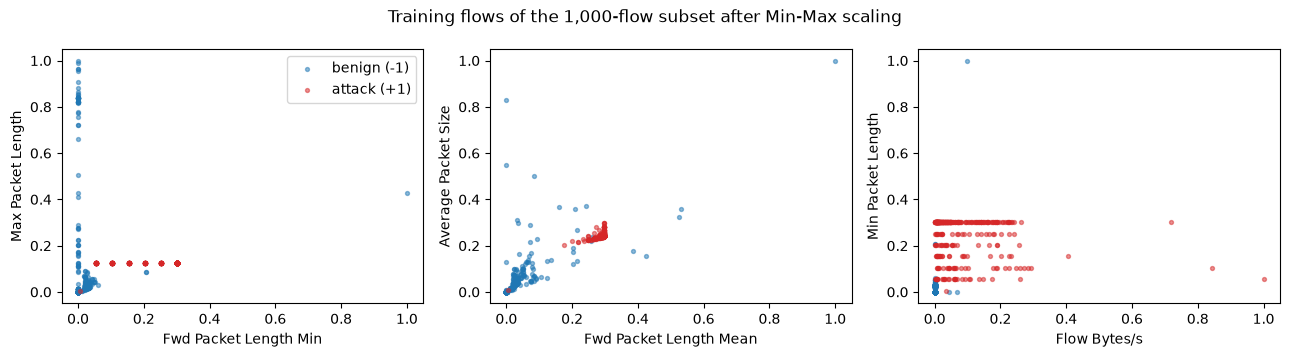

In [9]:
def encode(X_tr, X_te):
    # CHOICE: plain Min-Max to ANGLE_RANGE, fitted on the training split only
    scaler = MinMaxScaler(feature_range=ANGLE_RANGE).fit(X_tr[FEATURES])
    lo, hi = ANGLE_RANGE
    return (np.clip(scaler.transform(X_tr[FEATURES]), lo, hi),
            np.clip(scaler.transform(X_te[FEATURES]), lo, hi))

X0, y0 = balanced_subset(DATA_SIZES[0])
X_tr_raw, X_te_raw, y_tr_s, y_te_s = split(X0, y0, SEED)
X_train, X_test = encode(X_tr_raw, X_te_raw)
y_train, y_test = y_tr_s.to_numpy(), y_te_s.to_numpy()
print("Training flows:", X_train.shape, "  test flows:", X_test.shape)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (i, j) in zip(axes, [(0, 4), (1, 5), (2, 3)]):
    for cls, colour in [(0, "tab:blue"), (1, "tab:red")]:
        pts = X_train[y_train == cls]
        ax.scatter(pts[:, i], pts[:, j], s=8, alpha=0.5, c=colour, label=LABEL_NAMES[cls])
    ax.set_xlabel(FEATURES[i]); ax.set_ylabel(FEATURES[j])
axes[0].legend(); fig.suptitle(f"Training flows of the {DATA_SIZES[0]:,}-flow subset after Min-Max scaling")
plt.tight_layout(); plt.show()

Look at the middle panel: after Min-Max scaling, `Flow Bytes/s` is squeezed against zero for almost every flow, because a handful of flows have enormous values. The QNN will see almost no information in that qubit. Section 17 comes back to this.

## 9. Classical baselines on the same seven numbers

The paper compares its QNN only with numbers from other papers (Table 4), never with a classical model on its own data. We train four classical models on exactly the seven Min-Max numbers the QNN gets, and one random forest on all features, so that we can tell how hard the task is.

In [10]:
def evaluate(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0),
            "f1": f1_score(y_true, y_pred, zero_division=0)}

def classical_models(seed):
    return {"Random forest": RandomForestClassifier(n_estimators=100, random_state=seed),
            "SVM (RBF, C=1)": SVC(kernel="rbf", C=1.0),
            "Logistic regression": LogisticRegression(max_iter=1000),
            "MLP (16 hidden)": MLPClassifier(hidden_layer_sizes=(16,), max_iter=2000, random_state=seed)}

def run_baselines(X_tr, y_tr, X_te, y_te, seed, X_tr_all=None, X_te_all=None):
    out = {}
    for name, model in classical_models(seed).items():
        start = time.perf_counter()
        pred = model.fit(X_tr, y_tr).predict(X_te)
        out[name] = {**evaluate(y_te, pred), "time_s": seconds_since(start)}
    if X_tr_all is not None:
        start = time.perf_counter()
        pred = RandomForestClassifier(n_estimators=100, random_state=seed).fit(X_tr_all, y_tr).predict(X_te_all)
        out["Random forest, all features"] = {**evaluate(y_te, pred), "time_s": seconds_since(start)}
    return out

baselines_0 = run_baselines(X_train, y_train, X_test, y_test, SEED, X_tr_raw, X_te_raw)
pd.DataFrame(baselines_0).T.style.format("{:.4f}")

,accuracy,precision,recall,f1,time_s
Random forest,0.9933,1.0000,0.9867,0.9933,0.3140
"SVM (RBF, C=1)",0.9967,1.0000,0.9933,0.9967,0.0191
Logistic regression,0.9933,0.9933,0.9933,0.9933,0.0225
MLP (16 hidden),0.9967,1.0000,0.9933,0.9967,0.9128
"Random forest, all features",0.9967,1.0000,0.9933,0.9967,0.3300


## 10. The quantum circuit: feature map and ansatz

The paper's Figure 2 shows a `QNNCircuit` made of two blocks.

**ZZFeatureMap (data loading).** For each of the two repetitions: a Hadamard on every qubit, a phase `P(2·x_k)` on qubit `k`, and for every pair of qubits a CNOT, a phase `P(2·(π − x_i)(π − x_j))` and another CNOT. The pair terms are what "entangles the encoded features into pairs" in the paper's words. With `entanglement="linear"` the pairs are the six neighbouring qubits (0-1, 1-2, ..., 5-6); the library default `"full"` would connect all 21 pairs.

**RealAmplitudes (data processing).** Three repetitions of a CNOT ladder followed by a `Ry(θ)` rotation on every qubit, plus a final rotation layer: 4 × 7 = 28 trainable weights. Only real amplitudes are produced, hence the name.

**Measurement.** `EstimatorQNN` returns the expectation value of one observable. The library default, which the paper implicitly used, is `Z ⊗ Z ⊗ ... ⊗ Z` on all qubits: a number between −1 and +1 that equals the probability of an even number of 1s minus the probability of an odd number. The classifier takes its sign.

input parameters : 7 (one per feature)
trainable weights: 28
gates after decomposition: 110  depth: 42


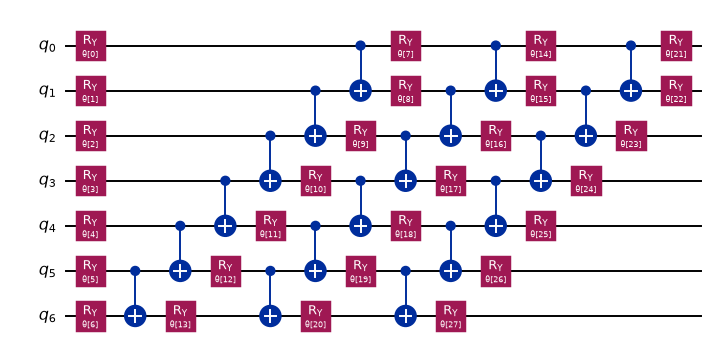

In [11]:
feature_map = zz_feature_map(N_QUBITS, reps=FM_REPS, entanglement=FM_ENTANGLEMENT)
ansatz = real_amplitudes(N_QUBITS, reps=ANSATZ_REPS, entanglement=ANSATZ_ENTANGLEMENT)
circuit, input_params, weight_params = qnn_circuit(feature_map=feature_map, ansatz=ansatz)
observable = SparsePauliOp("Z" * N_QUBITS)

print("input parameters :", len(input_params), "(one per feature)")
print("trainable weights:", len(weight_params))
print("gates after decomposition:", circuit.decompose().size(), " depth:", circuit.decompose().depth())
ansatz.draw("mpl", fold=-1, scale=0.7)

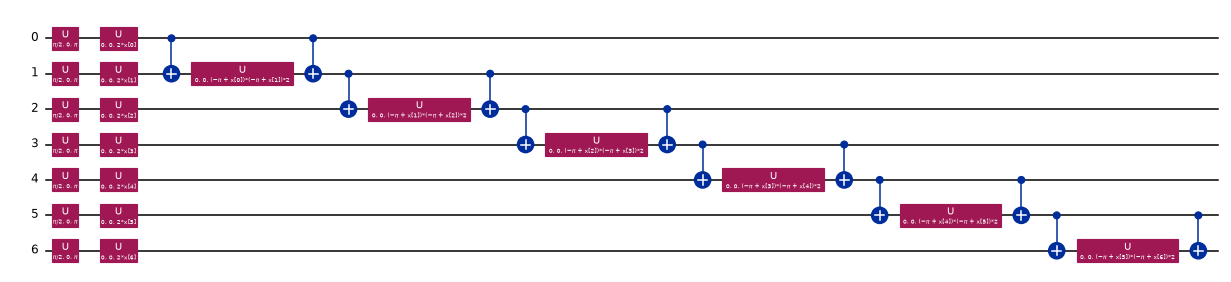

In [12]:
zz_feature_map(N_QUBITS, reps=1, entanglement=FM_ENTANGLEMENT).decompose().draw(
    "mpl", fold=70, scale=0.55)   # one repetition only, so that the pattern is readable

## 11. The QNN classifier

`EstimatorQNN` wraps the circuit and the estimator. `NeuralNetworkClassifier` wraps the QNN: it draws 28 random initial weights (uniform in [0, 1), seeded by `algorithm_globals`), and asks COBYLA to minimise the mean squared error between the expectation value and the label (+1 attack, −1 benign). COBYLA is derivative-free: with 28 weights its first 30 evaluations only build the initial simplex, so "100 iterations" leaves it 70 real steps. We log every loss value with a callback and redraw the curve while training runs.

Two things differ from the paper on purpose and are easy to change in the settings cell: we use Qiskit Aer's `EstimatorV2` (local, exact expectation values) instead of IBM's cloud `simulator_statevector` (retired in 2024), and `default_precision=0` so that no shot noise is simulated.

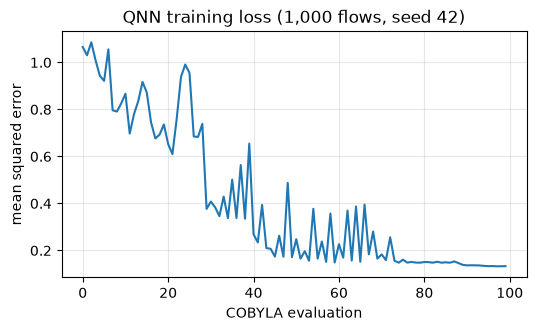

training took 75 s for 100 loss evaluations (loss 1.065 -> 0.133)
training accuracy 0.9786   test accuracy 0.9667   test F1 0.9673


In [13]:
def make_qnn(seed, precision=PRECISION, estimator=None):
    if estimator is None:
        estimator = AerEstimator(options={"backend_options": {"seed_simulator": seed},
                                          "default_precision": precision})
    return EstimatorQNN(circuit=circuit, estimator=estimator, observables=observable,
                        input_params=input_params, weight_params=weight_params,
                        default_precision=precision)

def to_pm1(y):          # 0/1 labels -> -1/+1 as in the Qiskit tutorial
    return np.where(np.asarray(y) == 1, 1, -1)

def train_qnn(X_tr, y_tr, seed, maxiter=MAXITER, live_plot=False, label=""):
    algorithm_globals.random_seed = seed
    losses = []
    def callback(weights, loss):
        losses.append(loss)
        if live_plot and (len(losses) % 25 == 0 or len(losses) == maxiter):
            clear_output(wait=True)
            plt.figure(figsize=(6, 3.2))
            plt.plot(losses); plt.xlabel("COBYLA evaluation"); plt.ylabel("mean squared error")
            plt.title(f"QNN training loss {label}"); plt.grid(alpha=0.3); plt.show()
    clf = NeuralNetworkClassifier(make_qnn(seed), loss="squared_error",
                                  optimizer=COBYLA(maxiter=maxiter), callback=callback)
    start = time.perf_counter()
    clf.fit(X_tr, to_pm1(y_tr))
    return clf, np.array(losses), seconds_since(start)

def qnn_predict(clf, X):
    return (clf.predict(X).ravel() > 0).astype(int)     # +1 -> attack (1), -1 -> benign (0)

clf_0, losses_0, time_0 = train_qnn(X_train, y_train, SEED, live_plot=True,
                                    label=f"({DATA_SIZES[0]:,} flows, seed {SEED})")
pred_0 = qnn_predict(clf_0, X_test)
train_acc_0 = accuracy_score(y_train, qnn_predict(clf_0, X_train))
qnn_0 = {**evaluate(y_test, pred_0), "time_s": time_0}
print(f"training took {time_0:.0f} s for {len(losses_0)} loss evaluations "
      f"(loss {losses_0[0]:.3f} -> {losses_0.min():.3f})")
print(f"training accuracy {train_acc_0:.4f}   test accuracy {qnn_0['accuracy']:.4f}   test F1 {qnn_0['f1']:.4f}")

## 12. Measuring performance

Every test flow lands in one of four boxes; the attack class is the positive class.

* really attack, predicted attack: **true positive (TP)**;
* really attack, predicted benign: **false negative (FN)**, a missed attack;
* really benign, predicted attack: **false positive (FP)**, a false alarm;
* really benign, predicted benign: **true negative (TN)**.

Accuracy = (TP + TN) / all, precision = TP / (TP + FP), recall = TP / (TP + FN), F1 = harmonic mean of precision and recall; these are the paper's Equations (3) to (6). In security, low recall means attacks get through and low precision means analysts drown in false alarms.

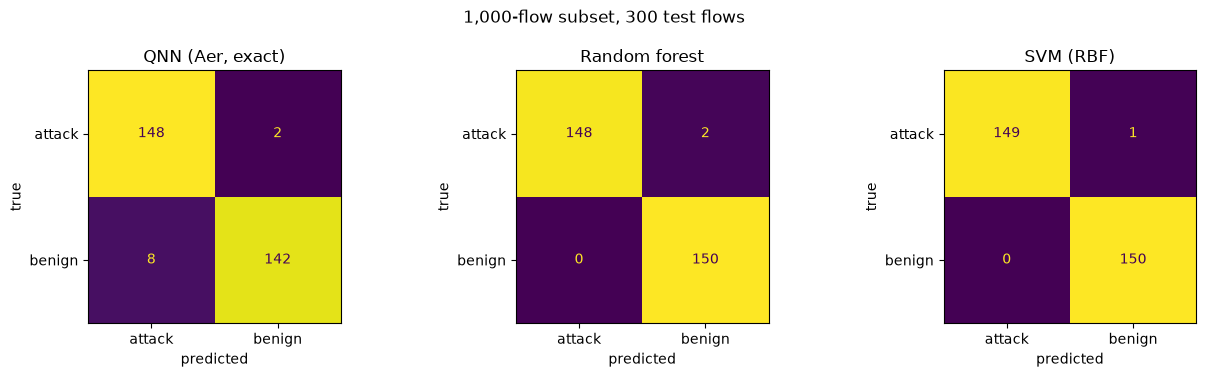

,accuracy,precision,recall,f1,time_s
"QNN (Aer, exact)",0.9667,0.9487,0.9867,0.9673,75.1213
Random forest,0.9933,1.0000,0.9867,0.9933,0.3140
"SVM (RBF, C=1)",0.9967,1.0000,0.9933,0.9967,0.0191
Logistic regression,0.9933,0.9933,0.9933,0.9933,0.0225
MLP (16 hidden),0.9967,1.0000,0.9933,0.9967,0.9128
"Random forest, all features",0.9967,1.0000,0.9933,0.9967,0.3300


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
rf_pred_0 = classical_models(SEED)["Random forest"].fit(X_train, y_train).predict(X_test)
svm_pred_0 = classical_models(SEED)["SVM (RBF, C=1)"].fit(X_train, y_train).predict(X_test)
for ax, (name, pred) in zip(axes, [("QNN (Aer, exact)", pred_0), ("Random forest", rf_pred_0),
                                   ("SVM (RBF)", svm_pred_0)]):
    cm = confusion_matrix(y_test, pred, labels=[1, 0])
    ConfusionMatrixDisplay(cm, display_labels=["attack", "benign"]).plot(ax=ax, colorbar=False)
    ax.set_title(name); ax.set_xlabel("predicted"); ax.set_ylabel("true")
fig.suptitle(f"{DATA_SIZES[0]:,}-flow subset, {len(y_test)} test flows"); plt.tight_layout(); plt.show()

summary_0 = pd.DataFrame({"QNN (Aer, exact)": qnn_0, **baselines_0}).T
summary_0.style.format("{:.4f}")

## 13. Is the model "platform independent"? Local statevector, Aer, and shot noise

The title of the paper promises platform independence, yet its central observation is that the *same* model scored 80.69 % "on a local computer" and 92.63 % "on the IBM statevector simulator", which the authors attribute to IBM's "higher precision arithmetic". We can test this directly. We take the weights just trained and evaluate the QNN on three platforms:

1. Qiskit Aer `EstimatorV2` (the one used for training);
2. Qiskit's reference `StatevectorEstimator` (pure Python/NumPy statevector, what a "local" run would use);
3. a by-hand NumPy implementation: the feature-map state `|φ(x)⟩` for each flow, the ansatz unitary `U(θ)`, and `⟨φ(x)| U† Z⊗7 U |φ(x)⟩`.

All three are exact simulations of the same circuit, so they must agree to machine precision. Then we switch on simulated shot noise (`precision = 1/64`, the standard error of a 4,096-shot estimate, which is also `EstimatorQNN`'s default) to see what *does* change predictions.

In [15]:
theta = clf_0.weights
qnn_aer = make_qnn(SEED)
qnn_sv = make_qnn(SEED, estimator=StatevectorEstimator(seed=SEED))

start = time.perf_counter(); out_aer = qnn_aer.forward(X_test, theta).ravel(); t_aer = seconds_since(start)
start = time.perf_counter(); out_sv = qnn_sv.forward(X_test, theta).ravel(); t_sv = seconds_since(start)

# by hand: |phi(x)> from the feature map, U(theta) from the ansatz, Z...Z is diagonal with parity signs
Z_diag = np.array([(-1) ** bin(i).count("1") for i in range(2 ** N_QUBITS)])
U = Operator(ansatz.assign_parameters(theta)).data
M = U.conj().T @ (Z_diag[:, None] * U)
start = time.perf_counter()
Phi = np.array([Statevector(feature_map.assign_parameters(x)).data for x in X_test])
out_hand = np.real(np.einsum("ni,ij,nj->n", Phi.conj(), M, Phi)); t_hand = seconds_since(start)

print(f"Aer EstimatorV2        {t_aer:6.2f} s")
print(f"StatevectorEstimator   {t_sv:6.2f} s   max |diff| vs Aer = {np.abs(out_sv - out_aer).max():.1e}")
print(f"NumPy by hand          {t_hand:6.2f} s   max |diff| vs Aer = {np.abs(out_hand - out_aer).max():.1e}")
same_predictions = all(np.array_equal(np.sign(out_aer), np.sign(o)) for o in (out_sv, out_hand))
print("identical predictions on all three platforms:", same_predictions)
platform_acc = {name: accuracy_score(y_test, (o > 0).astype(int))
                for name, o in [("Aer", out_aer), ("StatevectorEstimator", out_sv), ("by hand", out_hand)]}
print("accuracy per platform:", {k: round(v, 4) for k, v in platform_acc.items()})

# now with simulated shot noise: the same weights, five different noise seeds
noisy_acc = []
for s in range(5):
    out_noisy = make_qnn(SEED + s, precision=NOISE_PRECISION,
                         estimator=StatevectorEstimator(seed=SEED + s, default_precision=NOISE_PRECISION)
                         ).forward(X_test, theta).ravel()
    noisy_acc.append(accuracy_score(y_test, (out_noisy > 0).astype(int)))
print(f"accuracy with shot noise (precision {NOISE_PRECISION:.4f}, ~4,096 shots): "
      f"{np.mean(noisy_acc):.4f} ± {np.std(noisy_acc):.4f} over 5 noise seeds")
margin = np.abs(out_aer)
print(f"share of test flows with |<Z...Z>| < {NOISE_PRECISION:.4f} (undecidable with 4,096 shots): "
      f"{(margin < NOISE_PRECISION).mean():.3f}")

Aer EstimatorV2          0.31 s
StatevectorEstimator     2.95 s   max |diff| vs Aer = 4.2e-15
NumPy by hand            1.84 s   max |diff| vs Aer = 1.3e-14
identical predictions on all three platforms: True
accuracy per platform: {'Aer': 0.9667, 'StatevectorEstimator': 0.9667, 'by hand': 0.9667}


accuracy with shot noise (precision 0.0156, ~4,096 shots): 0.9667 ± 0.0000 over 5 noise seeds
share of test flows with |<Z...Z>| < 0.0156 (undecidable with 4,096 shots): 0.000


Exact simulation gives the same expectation values and the same predictions on every platform. A difference of twelve accuracy points between two ideal simulations of the same trained circuit cannot come from "numerical precision"; it can only come from a different run: different initial weights, a different data subset or split, or shot noise during training. Section 15 measures how much such run-to-run variation there is.

## 14. The data-size sweep: redrawing Table 3 and Figure 5

The paper trains the QNN on nested subsets of 1,000 to 16,000 flows and reports one confusion matrix per size (Figures 4 and 5) and one row of metrics per size (Table 3). We do the same, re-running the whole pipeline (split, scaling, training) for every size. The classical baselines run on the same inputs. In `FAST_MODE` only the two smallest sizes run.

In [16]:
PAPER_TABLE3 = pd.DataFrame({
    "flows": [1000, 2000, 4000, 8000, 16000],
    "paper local acc": [70.33, 73.67, 75.50, 79.63, 80.69],
    "paper local prec": [71.43, 71.04, 76.29, 81.78, 78.73],
    "paper local rec": [69.08, 74.56, 77.50, 79.28, 79.69],
    "paper local F1": [70.33, 72.76, 76.89, 80.50, 79.21],
    "paper simulator acc": [82.33, 85.83, 84.75, 87.54, 92.63],
    "paper simulator prec": [80.27, 87.07, 86.09, 87.80, 91.38],
    "paper simulator rec": [83.10, 86.25, 84.29, 88.56, 92.85],
    "paper simulator F1": [81.66, 86.66, 85.18, 88.18, 92.11],
}).set_index("flows")

sweep_rows, sweep_cms, sweep_losses = [], {}, {}
for n in DATA_SIZES:
    X_n, y_n = balanced_subset(n)
    Xtr_raw, Xte_raw, ytr, yte = split(X_n, y_n, SEED)
    Xtr, Xte = encode(Xtr_raw, Xte_raw)
    ytr, yte = ytr.to_numpy(), yte.to_numpy()
    if n == DATA_SIZES[0]:                       # already trained in Section 11 (same seed, same split)
        clf_n, losses_n, t_n = clf_0, losses_0, time_0
    else:
        clf_n, losses_n, t_n = train_qnn(Xtr, ytr, SEED)
    pred_n = qnn_predict(clf_n, Xte)
    sweep_cms[n] = confusion_matrix(yte, pred_n, labels=[1, 0])
    sweep_losses[n] = losses_n
    row = {"flows": n, "model": "QNN (Aer, exact)", **evaluate(yte, pred_n), "time_s": t_n,
           "train_acc": accuracy_score(ytr, qnn_predict(clf_n, Xtr))}
    sweep_rows.append(row)
    for name, res in run_baselines(Xtr, ytr, Xte, yte, SEED, Xtr_raw, Xte_raw).items():
        sweep_rows.append({"flows": n, "model": name, **res})
    print(f"{n:>6,} flows: QNN acc {row['accuracy']:.4f}  F1 {row['f1']:.4f}  "
          f"(train acc {row['train_acc']:.4f}, {t_n:.0f} s)   "
          f"paper simulator {PAPER_TABLE3.loc[n, 'paper simulator acc']:.2f} %, local {PAPER_TABLE3.loc[n, 'paper local acc']:.2f} %")

sweep = pd.DataFrame(sweep_rows)
table = sweep[sweep.model == "QNN (Aer, exact)"].set_index("flows")[["accuracy", "precision", "recall", "f1"]] * 100
table.columns = ["notebook acc", "notebook prec", "notebook rec", "notebook F1"]
pd.concat([PAPER_TABLE3.loc[DATA_SIZES], table], axis=1).round(2)

 1,000 flows: QNN acc 0.9667  F1 0.9673  (train acc 0.9786, 75 s)   paper simulator 82.33 %, local 70.33 %


 2,000 flows: QNN acc 0.9700  F1 0.9707  (train acc 0.9757, 163 s)   paper simulator 85.83 %, local 73.67 %


 4,000 flows: QNN acc 0.9867  F1 0.9868  (train acc 0.9911, 403 s)   paper simulator 84.75 %, local 75.50 %


 8,000 flows: QNN acc 0.9842  F1 0.9843  (train acc 0.9879, 1199 s)   paper simulator 87.54 %, local 79.63 %


16,000 flows: QNN acc 0.9933  F1 0.9934  (train acc 0.9894, 4153 s)   paper simulator 92.63 %, local 80.69 %


,paper local acc,paper local prec,paper local rec,paper local F1,paper simulator acc,paper simulator prec,paper simulator rec,paper simulator F1,notebook acc,notebook prec,notebook rec,notebook F1
flows,,,,,,,,,,,,
1000,70.33,71.43,69.08,70.33,82.33,80.27,83.10,81.66,96.67,94.87,98.67,96.73
2000,73.67,71.04,74.56,72.76,85.83,87.07,86.25,86.66,97.00,94.90,99.33,97.07
4000,75.50,76.29,77.50,76.89,84.75,86.09,84.29,85.18,98.67,97.56,99.83,98.68
8000,79.63,81.78,79.28,80.50,87.54,87.80,88.56,88.18,98.42,97.31,99.58,98.43
16000,80.69,78.73,79.69,79.21,92.63,91.38,92.85,92.11,99.33,99.05,99.62,99.34


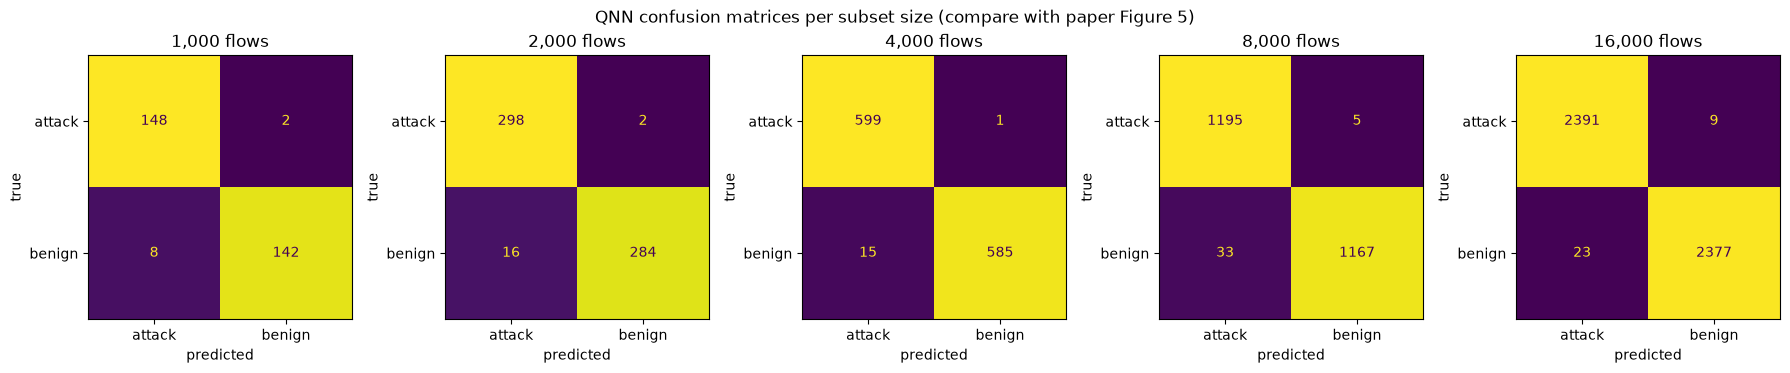

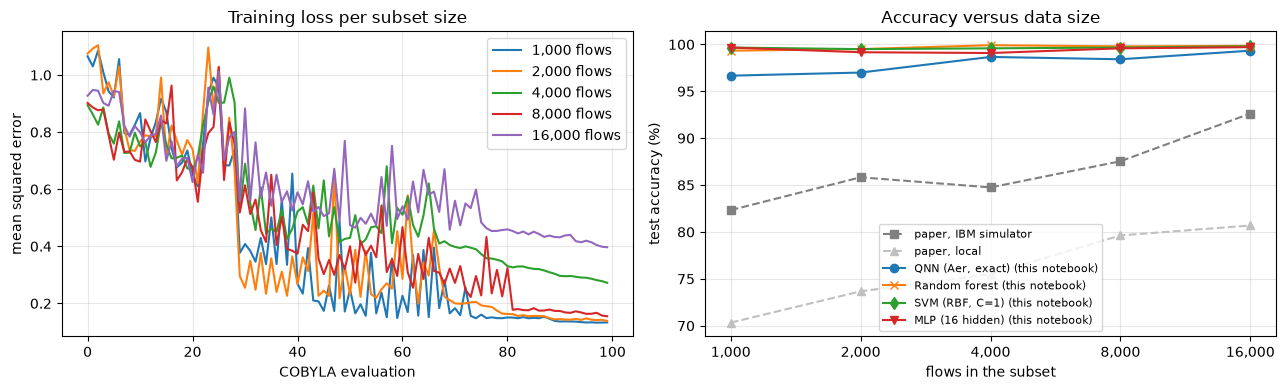

model,Logistic regression,MLP (16 hidden),"QNN (Aer, exact)",Random forest,"Random forest, all features","SVM (RBF, C=1)"
flows,,,,,,
1000,0.9933,0.9967,0.9667,0.9933,0.9967,0.9967
2000,0.9917,0.9917,0.9700,0.9950,0.9967,0.9950
4000,0.9883,0.9908,0.9867,0.9992,0.9983,0.9958
8000,0.9892,0.9958,0.9842,0.9979,0.9988,0.9967
16000,0.9950,0.9971,0.9933,0.9985,0.9990,0.9979


In [17]:
fig, axes = plt.subplots(1, len(DATA_SIZES), figsize=(3.6 * len(DATA_SIZES), 3.6))
for ax, n in zip(np.atleast_1d(axes), DATA_SIZES):
    ConfusionMatrixDisplay(sweep_cms[n], display_labels=["attack", "benign"]).plot(ax=ax, colorbar=False)
    ax.set_title(f"{n:,} flows"); ax.set_xlabel("predicted"); ax.set_ylabel("true")
fig.suptitle("QNN confusion matrices per subset size (compare with paper Figure 5)")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for n in DATA_SIZES:
    axes[0].plot(sweep_losses[n], label=f"{n:,} flows")
axes[0].set_xlabel("COBYLA evaluation"); axes[0].set_ylabel("mean squared error"); axes[0].legend()
axes[0].set_title("Training loss per subset size"); axes[0].grid(alpha=0.3)

axes[1].plot(PAPER_TABLE3.index, PAPER_TABLE3["paper simulator acc"], "s--", color="gray", label="paper, IBM simulator")
axes[1].plot(PAPER_TABLE3.index, PAPER_TABLE3["paper local acc"], "^--", color="silver", label="paper, local")
for name, marker in [("QNN (Aer, exact)", "o-"), ("Random forest", "x-"), ("SVM (RBF, C=1)", "d-"), ("MLP (16 hidden)", "v-")]:
    part = sweep[sweep.model == name]
    axes[1].plot(part.flows, part.accuracy * 100, marker, label=f"{name} (this notebook)")
axes[1].set_xscale("log", base=2); axes[1].set_xticks(PAPER_TABLE3.index); axes[1].set_xticklabels([f"{n:,}" for n in PAPER_TABLE3.index])
axes[1].set_xlabel("flows in the subset"); axes[1].set_ylabel("test accuracy (%)"); axes[1].grid(alpha=0.3)
axes[1].set_title("Accuracy versus data size"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

sweep.pivot(index="flows", columns="model", values="accuracy").round(4)

## 15. Run-to-run variation

The paper reports one number per size. How much do the numbers move when only the random split and the initial weights change? We repeat the smallest subset with `N_RUNS` seeds (the seed changes the train/test split, the initial weights and the baselines' randomness) and report mean ± standard deviation. The random forest and the SVM run on the same splits.

In [18]:
runs = []
n0 = DATA_SIZES[0]
X_n, y_n = balanced_subset(n0)
for run in range(N_RUNS):
    seed = SEED + run
    Xtr_raw, Xte_raw, ytr, yte = split(X_n, y_n, seed)
    Xtr, Xte = encode(Xtr_raw, Xte_raw)
    ytr, yte = ytr.to_numpy(), yte.to_numpy()
    if run == 0:
        clf_r, losses_r, t_r = clf_0, losses_0, time_0
    else:
        clf_r, losses_r, t_r = train_qnn(Xtr, ytr, seed)
    q = evaluate(yte, qnn_predict(clf_r, Xte))
    runs.append({"run": run + 1, "seed": seed, "model": "QNN (Aer, exact)", **q, "time_s": t_r})
    for name, res in run_baselines(Xtr, ytr, Xte, yte, seed).items():
        if name in ("Random forest", "SVM (RBF, C=1)"):
            runs.append({"run": run + 1, "seed": seed, "model": name, **res})
    print(f"run {run + 1} (seed {seed}): QNN acc {q['accuracy']:.4f}  F1 {q['f1']:.4f}  final loss {losses_r.min():.3f}")

runs = pd.DataFrame(runs)
stats = runs.groupby("model")[["accuracy", "precision", "recall", "f1"]].agg(["mean", "std"]).round(4)
stats

run 1 (seed 42): QNN acc 0.9667  F1 0.9673  final loss 0.133


run 2 (seed 43): QNN acc 0.9233  F1 0.9210  final loss 0.522


run 3 (seed 44): QNN acc 0.9667  F1 0.9675  final loss 0.170


run 4 (seed 45): QNN acc 0.9733  F1 0.9737  final loss 0.158


run 5 (seed 46): QNN acc 0.9733  F1 0.9740  final loss 0.157


accuracy         precision          recall              f1  \
                     mean     std      mean     std    mean     std    mean   
model                                                                         
QNN (Aer, exact)   0.9607  0.0211    0.9505  0.0065  0.9720  0.0443  0.9607   
Random forest      0.9947  0.0018    0.9973  0.0036  0.9920  0.0056  0.9946   
SVM (RBF, C=1)     0.9960  0.0015    0.9947  0.0055  0.9973  0.0037  0.9960   

                          
                     std  
model                     
QNN (Aer, exact)  0.0224  
Random forest     0.0018  
SVM (RBF, C=1)    0.0015

## 16. Side by side with the paper

The cell below prints the paper's numbers next to ours for every subset size this run covered and gives a verdict per claim. A metric counts as **reproduced** when our value is within 2 accuracy points (0.02 F1) of the paper's, **exceeded** when we are above that band and **not reached** when we are below it.

In [19]:
def verdict(ours, paper, tol):
    diff = float(np.subtract(ours, paper))
    if abs(diff) <= tol:
        return "reproduced"
    return f"exceeded (+{diff:.2f})" if diff > 0 else f"not reached ({diff:.2f})"

qnn_sweep = sweep[sweep.model == "QNN (Aer, exact)"].set_index("flows")
rows = []
for n in DATA_SIZES:
    acc, f1v = qnn_sweep.loc[n, "accuracy"] * 100, qnn_sweep.loc[n, "f1"] * 100
    rows.append({"flows": n,
                 "paper simulator acc": PAPER_TABLE3.loc[n, "paper simulator acc"], "notebook acc": round(acc, 2),
                 "verdict acc (vs simulator)": verdict(acc, PAPER_TABLE3.loc[n, "paper simulator acc"], 2.0),
                 "verdict acc (vs local)": verdict(acc, PAPER_TABLE3.loc[n, "paper local acc"], 2.0),
                 "paper simulator F1": PAPER_TABLE3.loc[n, "paper simulator F1"], "notebook F1": round(f1v, 2),
                 "verdict F1 (vs simulator)": verdict(f1v, PAPER_TABLE3.loc[n, "paper simulator F1"], 2.0),
                 "RF acc (same inputs)": round(sweep[(sweep.flows == n) & (sweep.model == "Random forest")].accuracy.iloc[0] * 100, 2),
                 "SVM acc (same inputs)": round(sweep[(sweep.flows == n) & (sweep.model == "SVM (RBF, C=1)")].accuracy.iloc[0] * 100, 2)})
comparison = pd.DataFrame(rows).set_index("flows")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)
print(comparison.to_string())
print()

# claim 1: the headline number
if 16000 in DATA_SIZES:
    acc16 = qnn_sweep.loc[16000, "accuracy"] * 100
    print(f"Claim 1, 92.63 % accuracy with 16,000 flows on the simulator: {verdict(acc16, 92.63, 2.0)} "
          f"(notebook {acc16:.2f} %)")
else:
    biggest = max(DATA_SIZES)
    print(f"Claim 1, 92.63 % accuracy with 16,000 flows: cannot be checked in FAST_MODE "
          f"(largest subset here {biggest:,} flows, notebook {qnn_sweep.loc[biggest, 'accuracy']*100:.2f} % "
          f"vs paper {PAPER_TABLE3.loc[biggest, 'paper simulator acc']:.2f} % at that size). Set FAST_MODE = False.")

# claim 2: every row of Table 3 (simulator column) at the sizes we ran
n_rep = sum(v == "reproduced" for v in comparison["verdict acc (vs simulator)"])
print(f"Claim 2, Table 3 simulator accuracies: {n_rep} of {len(DATA_SIZES)} sizes reproduced within 2 points; "
      f"mean difference notebook - paper = {(comparison['notebook acc'] - comparison['paper simulator acc']).mean():+.2f} points")
n_rep_local = sum(v == "reproduced" for v in comparison["verdict acc (vs local)"])
print(f"         Table 3 local accuracies: {n_rep_local} of {len(DATA_SIZES)} sizes reproduced within 2 points")

# claim 3: accuracy grows with the amount of data
accs = qnn_sweep.loc[DATA_SIZES, "accuracy"].to_numpy()
trend = "increases" if np.all(np.diff(accs) >= 0) else ("decreases" if np.all(np.diff(accs) <= 0) else "is not monotonic")
print(f"Claim 3, accuracy increases with data size: in this run accuracy {trend} "
      f"({' -> '.join(f'{a*100:.2f}' for a in accs)} %) over {len(DATA_SIZES)} sizes")

# claim 4: simulator beats local because of numerical precision
print(f"Claim 4, simulator 12 points better than local run due to numerical precision: not supported; "
      f"Aer, StatevectorEstimator and NumPy give identical predictions here ({'yes' if same_predictions else 'no'}), "
      f"while run-to-run std at {n0:,} flows is {stats.loc['QNN (Aer, exact)', ('accuracy', 'std')]*100:.2f} points")

# claim 5: high accuracy with only seven features
gap_rf = (comparison["RF acc (same inputs)"] - comparison["notebook acc"]).mean()
print(f"Claim 5, QNN reaches high accuracy with seven features: the QNN reaches {comparison['notebook acc'].max():.2f} % at best, "
      f"but a random forest on the same seven numbers is {gap_rf:+.2f} points better on average "
      f"(SVM: {(comparison['SVM acc (same inputs)'] - comparison['notebook acc']).mean():+.2f})")
print(f"Repeated runs at {n0:,} flows: QNN {stats.loc['QNN (Aer, exact)', ('accuracy', 'mean')]*100:.2f} "
      f"± {stats.loc['QNN (Aer, exact)', ('accuracy', 'std')]*100:.2f} %, "
      f"RF {stats.loc['Random forest', ('accuracy', 'mean')]*100:.2f} ± {stats.loc['Random forest', ('accuracy', 'std')]*100:.2f} %")

       paper simulator acc  notebook acc verdict acc (vs simulator) verdict acc (vs local)  paper simulator F1  notebook F1 verdict F1 (vs simulator)  RF acc (same inputs)  SVM acc (same inputs)
flows                                                                                                                                                                                             
1000                 82.33         96.67          exceeded (+14.34)      exceeded (+26.34)               81.66        96.73         exceeded (+15.07)                 99.33                  99.67
2000                 85.83         97.00          exceeded (+11.17)      exceeded (+23.33)               86.66        97.07         exceeded (+10.41)                 99.50                  99.50
4000                 84.75         98.67          exceeded (+13.92)      exceeded (+23.17)               85.18        98.68         exceeded (+13.50)                 99.92                  99.58
8000                 87.5

## 17. Reading the paper critically

**The platform claim.** The paper's main numerical finding, 80.69 % locally against 92.63 % on IBM's simulator for the same model, is explained by "higher precision arithmetic and more stable numerical techniques" on IBM's side. Section 13 shows that three independent exact simulations of the trained circuit agree to about 1e-15 and give identical predictions. Double-precision arithmetic is the same on every platform; what differs between two runs is the random initial point, the data subset, the split, and whether shot noise was on. The IBM Runtime Estimator the paper used defaults to 4,000 shots, which adds noise of about ±0.016 to every expectation value, so the "simulator" run was, if anything, the *less* precise one. The title's "platform independence" is true in the opposite sense from how the paper argues it: an exact simulation gives the same answer everywhere.

**No classical baseline.** The paper compares only with other publications (Table 4) that used different subsets and features. On the identical seven Min-Max numbers, a random forest or an RBF SVM needs no quantum circuit to reach or exceed the QNN's accuracy (Sections 9 and 14). The honest statement is that seven well-chosen features separate reflection-attack flows almost perfectly, and that the QNN with 28 weights is a weaker classifier than a random forest on this input.

**Two of the seven features are the same column.** `Avg Fwd Segment Size` is `Fwd Packet Length Mean` under another name (they have identical F scores in Section 7), and `Min Packet Length` equals `Fwd Packet Length Min` for most flows. The QNN effectively receives five or six distinct numbers. The paper says it removed "repeated" columns, yet `SelectKBest` returned both twins, which it will always do because their scores are equal.

**Min-Max on a heavy-tailed feature.** `Flow Bytes/s` spans ten orders of magnitude; after Min-Max scaling almost every value is below 0.01, so one qubit is essentially idle (Section 8). A log transform before scaling, or a rank transform, would give the circuit something to work with. The paper reports this feature as one of the seven most informative, which the F score indeed suggests on raw values, but the encoding then throws the information away.

**COBYLA with 100 evaluations.** `maxiter=100` in Qiskit's COBYLA counts function evaluations. With 28 weights, the first 30 only build the initial simplex, so the optimiser takes about 70 steps in a 28-dimensional space. The loss curves in Section 14 are still falling when training stops, and the training accuracy is far from 100 %. The model is under-trained rather than overfitted, contrary to the paper's suggestion that larger subsets "can lead to overfitting".

**Which attack is being detected matters more than the model.** The paper never names the attack types in its subset. On the NTP reflection file used here, the paper's seven packet-length features are among the most informative ones and every model, classical or quantum, scores far above the paper's numbers. When we ran the identical notebook on the UDP-Lag file (`HF_FILES = ["01-12/UDPLag.csv"]`, Exercise 9), `SelectKBest` ranked the paper's features between 11th and 62nd, the QNN reached 80 to 82 % and a random forest on the same seven numbers only 83 %, while a random forest on all features reached 99 %. The paper's 82 to 93 % therefore says more about which flows were in its subset than about the QNN.

**What "16,000 samples" means.** CIC-DDoS2019 has about 50 million flows; the paper's largest subset is 0.03 % of it and, after duplicates are removed, benign flows are the scarce class (the NTP file has 13,317 distinct benign flows among 1.2 million). Results on such a subset say little about the full dataset or about live traffic.

**Deduced details.** The paper never states its train/test split, but every accuracy in Table 3 is an exact fraction of 30 % of the subset size (4446/4800, 2101/2400, 1017/1200, 515/600, 247/300), so a 70/30 split is certain. Repetitions and entanglement of the feature map and ansatz, the observable, the loss and the initial point are not given; this notebook uses the library defaults the authors most likely inherited from the Qiskit tutorial.

**What to take away.** When a paper reports a surprising gap between two runs of the same deterministic computation, look for a difference in the runs before accepting an explanation about hardware. And always ask for a classical model on the same inputs: a method is only interesting if it beats that.

## 18. Exercises

1. Set `ANGLE_RANGE = (0, np.pi)` and retrain. Does the QNN get better or worse? Why might large angles hurt a feature map whose two-qubit phases contain `(π − x_i)(π − x_j)`?
2. Apply `np.log1p` to `Flow Bytes/s` before Min-Max scaling (edit `encode`). How much does the QNN gain? How much does the random forest gain?
3. Replace `Avg Fwd Segment Size` by the next feature of your own `SelectKBest` ranking (Section 7) so that the seven inputs are distinct. Does accuracy change?
4. Increase `MAXITER` to 300 for the 1,000-flow subset. Where does the loss curve flatten? Compare the training and test accuracy before and after.
5. Train with shot noise: set `PRECISION = 1/64` (the `EstimatorQNN` default). How much does the test accuracy move between seeds compared with Section 15?
6. Change `FM_ENTANGLEMENT` to `"full"` (the library default, 21 qubit pairs per repetition) and then `ANSATZ_REPS` to 1. How does the training time change, how many weights are left, and does the accuracy move?
7. Replace `real_amplitudes` with `efficient_su2` (two rotation gates per qubit) and compare the loss curves.
8. The paper calls its model "platform independent". After Section 13, write one paragraph on what that phrase can and cannot mean for a simulated QNN, and what would change on real hardware.
9. Set `HF_FILES = ["01-12/UDPLag.csv"]` (158 MB) and run again. Compare the `SelectKBest` ranking of the paper's features, the QNN accuracy and the baselines with the NTP results. Which attack is harder to detect from packet lengths, and why?